# Лабораторная работа № 1
## Задание №3
> Григорьев Никита M3338, Паховский Иван M3339


In [118]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [119]:
def get_sample_mean(array):
    return np.mean(array)


def get_sample_variance(array):
    sample_mean = get_sample_mean(array)
    return np.mean((array - sample_mean) ** 2)

In [120]:
def get_info(array, message):
    sample_mean = get_sample_mean(array)
    sample_variance = get_sample_variance(array)
    standard_deviation = np.sqrt(sample_variance)
    median = np.median(array)
    minimum = np.min(array)
    maximum = np.max(array)
    lower_quartile = np.quantile(array, 0.25)
    upper_quartile = np.quantile(array, 0.75)
    iqr = upper_quartile - lower_quartile

    print(f"============== {message} ==============")
    print(f"Выборочное среднее: {sample_mean:.3f}")
    print(f"Выборочная дисперсия: {sample_variance:.3f}")
    print(f"Стандартное отклонение: {standard_deviation:.3f}")
    print(f"Медиана: {median:.3f}")
    print(f"Минимум: {minimum:.3f}")
    print(f"Максимум: {maximum:.3f}")
    print(f"Нижний квартиль: {lower_quartile:.3f}")
    print(f"Верхний квартиль: {upper_quartile:.3f}")
    print(f"Межквартильный размах: {iqr:.3f}")

In [121]:
df = pd.read_csv("smoking.csv")

xs = np.asarray(df["hemoglobin"])

get_info(xs, "Характеристика Hb среди людей")


============== Характеристика Hb среди людей ==============
Выборочное среднее: 14.623
Выборочная дисперсия: 2.448
Стандартное отклонение: 1.564
Медиана: 14.800
Минимум: 4.900
Максимум: 21.100
Нижний квартиль: 13.600
Верхний квартиль: 15.800
Межквартильный размах: 2.200


In [122]:
for smoking, group in df.groupby("smoking"):
    get_info(np.asarray(group["hemoglobin"]), f"Характеристика Hb для : {"курящих" if smoking else "не курящих" }")

============== Характеристика Hb для : не курящих ==============
Выборочное среднее: 14.145
Выборочная дисперсия: 2.496
Стандартное отклонение: 1.580
Медиана: 14.200
Минимум: 4.900
Максимум: 19.600
Нижний квартиль: 13.100
Верхний квартиль: 15.300
Межквартильный размах: 2.200
============== Характеристика Hb для : курящих ==============
Выборочное среднее: 15.445
Выборочная дисперсия: 1.294
Стандартное отклонение: 1.138
Медиана: 15.500
Минимум: 7.100
Максимум: 21.100
Нижний квартиль: 14.800
Верхний квартиль: 16.200
Межквартильный размах: 1.400


In [123]:
def empirical_distribution_function(x, xs):
    return np.sum(xs <= x) / np.size(xs)

In [124]:
def show_empirical_distribution_function(xs, message):
    sorted_xs = np.sort(xs)

    edf_values = [
        empirical_distribution_function(x, xs)
        for x in sorted_xs
    ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].step(sorted_xs, edf_values, where="post")
    axes[0].set_title("Эмпирическая функция распределения")
    axes[0].set_xlabel(f"Hb {message}")
    axes[0].set_ylabel(r"$F_n(x)$")
    axes[0].grid()

    axes[1].hist(xs, bins="auto", edgecolor="black")
    axes[1].set_title(f"Гистограмма Hb {message}")
    axes[1].set_xlabel(f"Hb {message}")
    axes[1].set_ylabel("Число людей")
    axes[1].grid(axis="y")

    plt.tight_layout()
    plt.show()

============== Эмпирическая функция распределения Hb для всех людей из выборки ==============


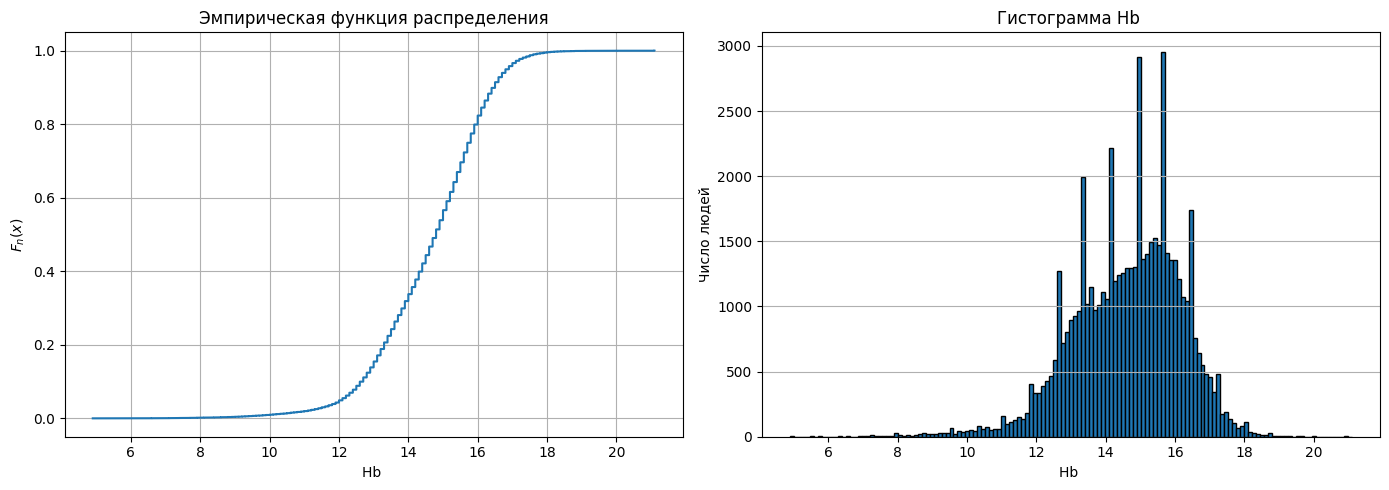

In [125]:
print("============== Эмпирическая функция распределения Hb для всех людей из выборки ==============")
show_empirical_distribution_function(xs, "")

============== Эмпирическая функция распределения Hb для не курящих ==============


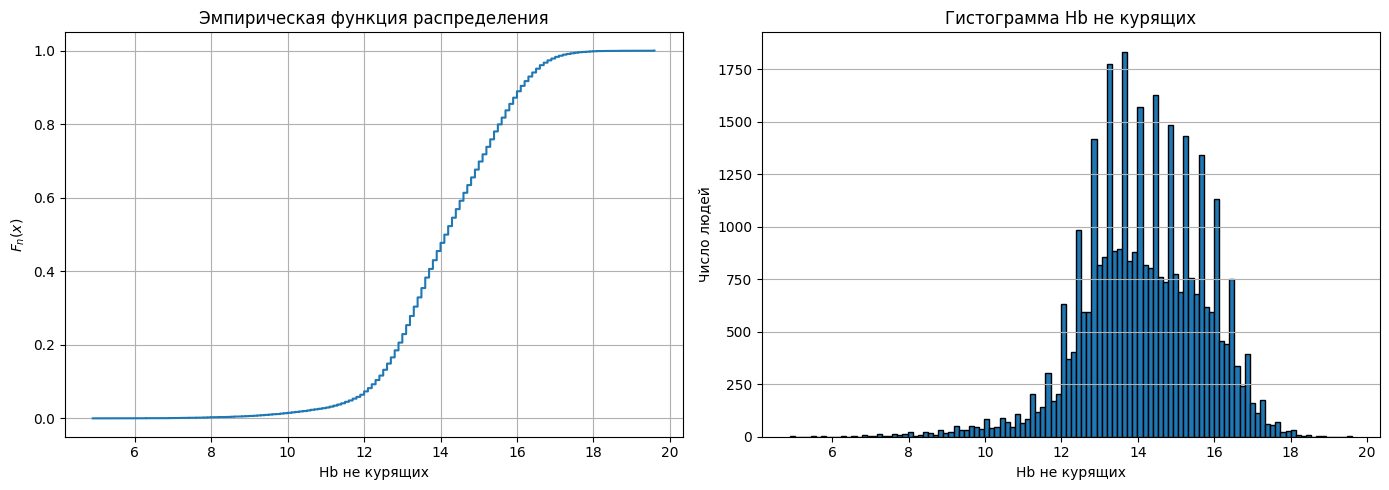

============== Эмпирическая функция распределения Hb для курящих ==============


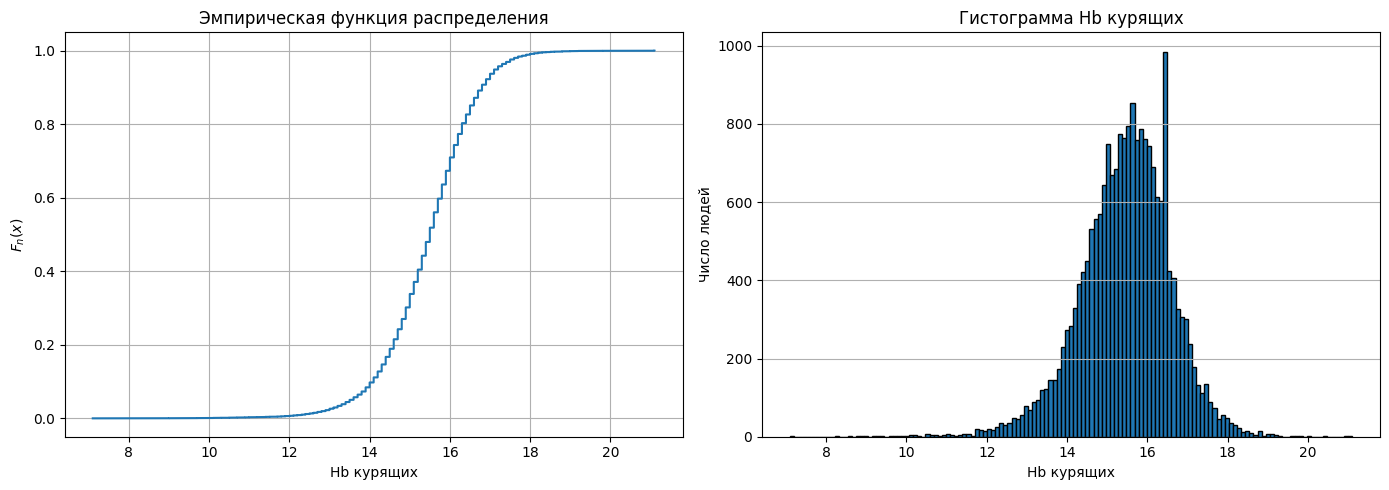

In [126]:

for smoking, group in df.groupby("smoking"):
    print(f"============== Эмпирическая функция распределения Hb для {"курящих" if smoking else "не курящих"} ==============")
    show_empirical_distribution_function(group["hemoglobin"], "курящих" if smoking else "не курящих")
